# Computer Vision — Section 2 Solutions

<a href="https://colab.research.google.com/github/amr-elgharip2006/cv-section2-tasks/blob/main/CV_Section2_Solutions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Student:** Amr Ahmed Elgharip — solutions only. Run all cells from the top.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)


OpenCV version: 5.0.0
NumPy version: 2.1.3


In [2]:
# Create a simple teaching image.
# This is only a starting image; image reading was already covered in Section 1.

h, w = 400, 600
img = np.ones((h, w, 3), dtype=np.uint8) * 240

# OpenCV colors are BGR.
cv2.rectangle(img, (50, 60), (250, 260), (255, 0, 0), -1)      # Blue
cv2.circle(img, (430, 160), 90, (0, 255, 0), -1)               # Green
cv2.rectangle(img, (280, 280), (520, 350), (0, 0, 255), -1)   # Red
cv2.putText(img, "OpenCV", (55, 390),
            cv2.FONT_HERSHEY_SIMPLEX, 1.2, (0, 0, 0), 2)

print("Teaching image:", img.shape, img.dtype)


Teaching image: (400, 600, 3) uint8


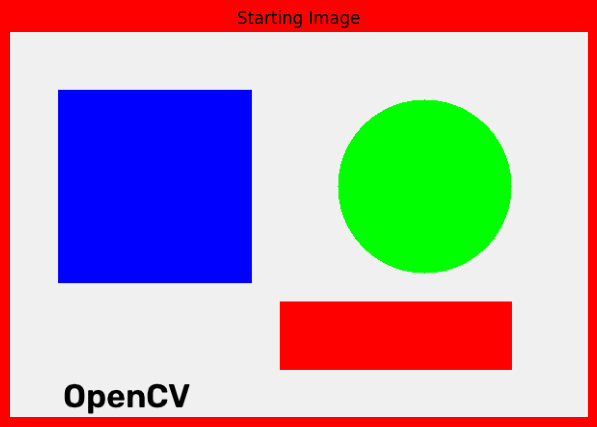

In [3]:
def show_bgr(image, title="Image", figsize=(8, 5)):
    """Display a BGR image correctly with Matplotlib."""
    fig = plt.figure(figsize=figsize, facecolor='red')
    ax = plt.gca()
    ax.set_facecolor('red')

    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
    plt.show()

show_bgr(img, "Starting Image")


# Solutions — Amr

All solutions below use the synthetic teaching image `img` from the **Setup** section, so they run without uploading any file (run the three Setup cells first: imports, `img`, `show_bgr`).

In [51]:
# Helper for the solutions: show several images in ONE compact subplot grid
# (instead of many separate figures). Works for BGR color images and 2-D gray/mask images.
def show_grid(images, titles, cols=3, cell_size=(4.6, 3.2), suptitle=None, title_size=10):
    rows = int(np.ceil(len(images) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cell_size[0] * cols, cell_size[1] * rows),
                             dpi=80, facecolor="white")
    axes = np.atleast_1d(axes).ravel()
    for ax, image, title in zip(axes, images, titles):
        if image.ndim == 2:                      # grayscale image or binary mask
            ax.imshow(image, cmap="gray", vmin=0, vmax=255)
        else:                                    # OpenCV BGR -> RGB for Matplotlib
            ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        ax.set_title(title, fontsize=title_size)
        ax.axis("off")
    for ax in axes[len(images):]:                # hide unused grid cells
        ax.axis("off")
    if suptitle:
        fig.suptitle(suptitle, fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()

print("Working image:", img.shape, img.dtype)

Working image: (400, 600, 3) uint8


### Task 1 — Resize (Solution)

Create a `150 × 100` version (remember: `dsize = (width, height)`), a 70 % version and a 130 % version, then compare the interpolation methods.

Original  -> shape (400, 600, 3)   (width=600, height=400)
150 x 100 -> shape (100, 150, 3)   (width=150, height=100)
70 %      -> shape (280, 420, 3)   (width=420, height=280)
130 %     -> shape (520, 780, 3)   (width=780, height=520)


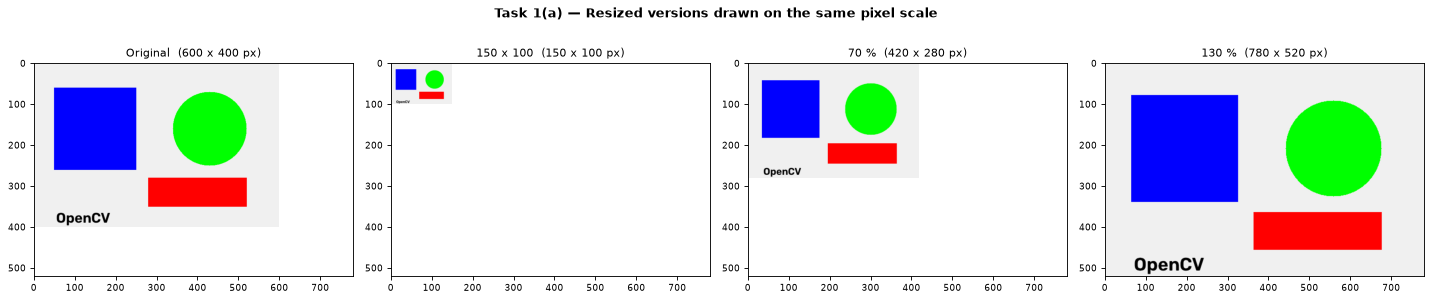

In [52]:
# (a) Three resized versions
fixed_150x100 = cv2.resize(img, (150, 100), interpolation=cv2.INTER_AREA)        # dsize = (width, height)
scaled_70 = cv2.resize(img, None, fx=0.7, fy=0.7, interpolation=cv2.INTER_AREA)    # shrink  -> AREA
scaled_130 = cv2.resize(img, None, fx=1.3, fy=1.3, interpolation=cv2.INTER_CUBIC)  # enlarge -> CUBIC

versions = {"Original": img, "150 x 100": fixed_150x100, "70 %": scaled_70, "130 %": scaled_130}
for name, im in versions.items():
    print(f"{name:9s} -> shape {im.shape}   (width={im.shape[1]}, height={im.shape[0]})")

# plt.imshow() stretches every image to fill its subplot, so here all subplots get the
# SAME axis limits (the size of the largest image) -> the real size difference is visible.
max_h, max_w = scaled_130.shape[:2]
fig, axes = plt.subplots(1, 4, figsize=(18, 3.9), dpi=80, facecolor="white")
for ax, (name, im) in zip(axes, versions.items()):
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
    ax.set_xlim(0, max_w)
    ax.set_ylim(max_h, 0)
    ax.set_title(f"{name}  ({im.shape[1]} x {im.shape[0]} px)", fontsize=10)
    ax.tick_params(labelsize=8)
fig.suptitle("Task 1(a) — Resized versions drawn on the same pixel scale", fontweight="bold")
plt.tight_layout()
plt.show()

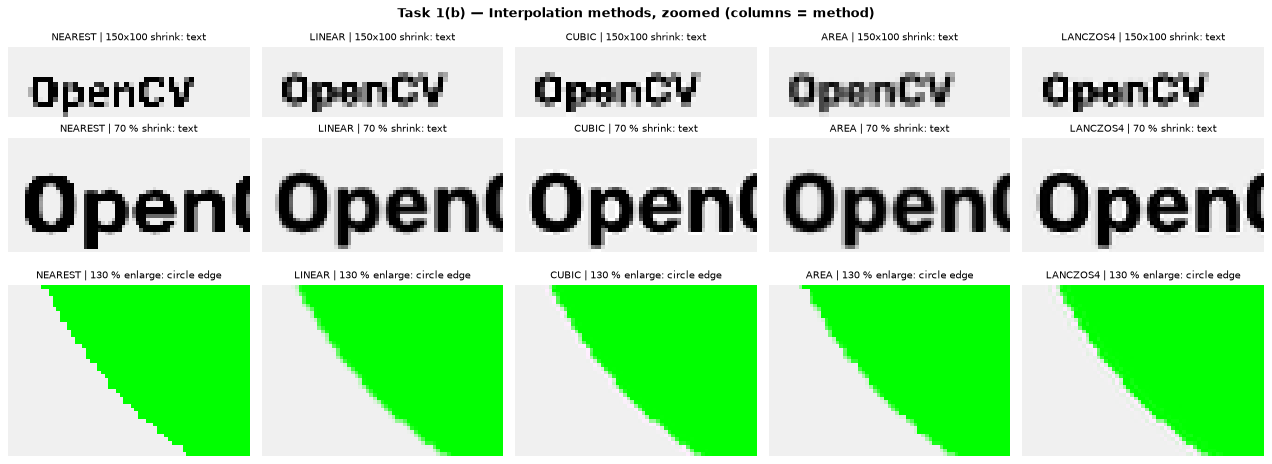

method          70 % shape     130 % shape   ms per 130 % resize
NEAREST      (280, 420, 3)   (520, 780, 3)                 0.114
LINEAR       (280, 420, 3)   (520, 780, 3)                 0.176
CUBIC        (280, 420, 3)   (520, 780, 3)                 0.389
AREA         (280, 420, 3)   (520, 780, 3)                 0.215
LANCZOS4     (280, 420, 3)   (520, 780, 3)                 0.819

2x enlarge: AREA result identical to NEAREST -> True


In [53]:
# (b) Compare the 5 interpolation methods for SHRINKING and ENLARGING.
# The differences are only a few pixels wide, so every tile zooms into a small region
# and is drawn with interpolation="nearest" (Matplotlib then shows the real pixels).
import time

methods = {
    "NEAREST": cv2.INTER_NEAREST,
    "LINEAR": cv2.INTER_LINEAR,
    "CUBIC": cv2.INTER_CUBIC,
    "AREA": cv2.INTER_AREA,
    "LANCZOS4": cv2.INTER_LANCZOS4,
}

tests = [
    # (row label,                  dsize,      scale, zoom region (x1, y1, x2, y2) in ORIGINAL coords)
    ("150x100 shrink: text",       (150, 100), 0.25,  (40, 346, 232, 398)),
    ("70 % shrink: text",          None,       0.7,   (50, 352, 150, 398)),
    ("130 % enlarge: circle edge", None,       1.3,   (342, 200, 392, 235)),
]

def zoom(image, region, scale):
    # Cut the region (given in original-image coordinates) out of a resized image.
    x1, y1, x2, y2 = [int(round(v * scale)) for v in region]
    return image[y1:y2, x1:x2]

ratios = [(r[3] - r[1]) / (r[2] - r[0]) for *_, r in tests]       # keep each row's aspect ratio
fig, axes = plt.subplots(len(tests), len(methods), figsize=(16, 3.2 * sum(ratios) + 1.5), dpi=80,
                         facecolor="white", gridspec_kw={"height_ratios": ratios})
for c, (name, method) in enumerate(methods.items()):
    for r, (label, dsize, scale, region) in enumerate(tests):
        if dsize is not None:
            out = cv2.resize(img, dsize, interpolation=method)
        else:
            out = cv2.resize(img, None, fx=scale, fy=scale, interpolation=method)
        axes[r, c].imshow(cv2.cvtColor(zoom(out, region, scale), cv2.COLOR_BGR2RGB),
                          interpolation="nearest")
        axes[r, c].set_title(f"{name} | {label}", fontsize=9)
        axes[r, c].axis("off")
fig.suptitle("Task 1(b) — Interpolation methods, zoomed (columns = method)", fontweight="bold")
plt.tight_layout()
plt.show()

# Speed comparison (absolute times depend on the machine; the ranking is what matters)
print(f"{'method':10s} {'70 % shape':>15s} {'130 % shape':>15s} {'ms per 130 % resize':>21s}")
for name, method in methods.items():
    s70 = cv2.resize(img, None, fx=0.7, fy=0.7, interpolation=method).shape
    t0 = time.perf_counter()
    for _ in range(50):
        s130 = cv2.resize(img, None, fx=1.3, fy=1.3, interpolation=method).shape
    ms = (time.perf_counter() - t0) / 50 * 1000
    print(f"{name:10s} {str(s70):>15s} {str(s130):>15s} {ms:21.3f}")

# INTER_AREA does not smooth when enlarging: at 2x it gives exactly the NEAREST result
area_2x = cv2.resize(img, None, fx=2, fy=2, interpolation=cv2.INTER_AREA)
nearest_2x = cv2.resize(img, None, fx=2, fy=2, interpolation=cv2.INTER_NEAREST)
print("\n2x enlarge: AREA result identical to NEAREST ->", np.array_equal(area_2x, nearest_2x))

**Conclusion — which interpolation for which job?**

| Situation | Best choice | Why |
|---|---|---|
| **Shrinking** (70 %, 150 × 100) | `INTER_AREA` | Every output pixel is the *average of all source pixels it covers*, so fine details (the text) are smoothed instead of randomly dropped → no aliasing / jagged artifacts. |
| **Enlarging** (130 %) | `INTER_CUBIC` or `INTER_LANCZOS4` | They fit a smooth curve through a 4×4 (cubic) or 8×8 (Lanczos) neighbourhood → smooth, sharp edges. `LANCZOS4` is the sharpest but the slowest. |
| Fast general default | `INTER_LINEAR` | Good speed/quality compromise (OpenCV's default), but it only looks at 2×2 pixels, so it aliases when shrinking a lot. |
| Masks / label maps | `INTER_NEAREST` | Copies one existing pixel → never invents new values (class IDs stay valid), but looks **blocky** when enlarging and **breaks thin details** (see the text) when shrinking. |

Note: `INTER_AREA` does not really smooth when *enlarging* — at an integer factor (2×) its result is identical to `INTER_NEAREST` (checked above) — so it is only recommended for shrinking.

### Task 2 — Crop / ROI (Solution)

Three ROIs taken with NumPy slicing `image[y1:y2, x1:x2]` (rows first, then columns), each with a 10 px margin around the object.

Blue square   -> img[50:271, 40:261]  shape = (221, 221, 3)
Green circle  -> img[60:261, 330:531]  shape = (201, 201, 3)
Red rectangle -> img[270:361, 270:531]  shape = (91, 261, 3)


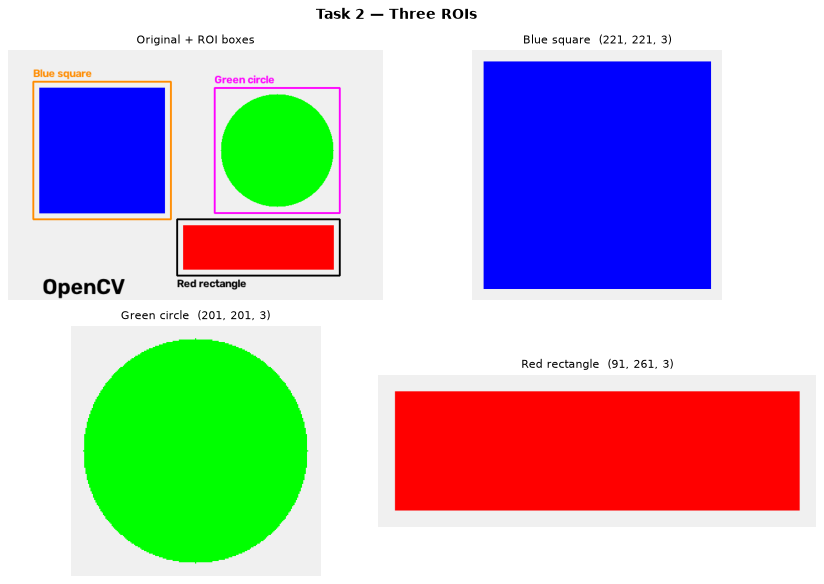

In [54]:
# ROI boxes as (x1, y1, x2, y2) in pixel coordinates, taken from how img was drawn (+10 px margin)
rois = {
    "Blue square":   (40, 50, 261, 271),     # square drawn from (50, 60) to (250, 260)
    "Green circle":  (330, 60, 531, 261),    # circle: center (430, 160), radius 90
    "Red rectangle": (270, 270, 531, 361),   # rectangle drawn from (280, 280) to (520, 350)
}
box_colors = {"Blue square": (0, 140, 255), "Green circle": (255, 0, 255), "Red rectangle": (0, 0, 0)}

crops = {}
for name, (x1, y1, x2, y2) in rois.items():
    crops[name] = img[y1:y2, x1:x2].copy()      # slicing = [rows (y), cols (x)]; .copy() -> independent array
    print(f"{name:13s} -> img[{y1}:{y2}, {x1}:{x2}]  shape = {crops[name].shape}")

# Show where each ROI is: draw the rectangles on a COPY of the original
roi_preview = img.copy()
for name, (x1, y1, x2, y2) in rois.items():
    cv2.rectangle(roi_preview, (x1, y1), (x2 - 1, y2 - 1), box_colors[name], 2)   # x2/y2 are exclusive in slicing
    label_y = y2 + 18 if name == "Red rectangle" else y1 - 7     # red label below its box (more space)
    cv2.putText(roi_preview, name, (x1, label_y), cv2.FONT_HERSHEY_SIMPLEX, 0.6,
                box_colors[name], 2, cv2.LINE_AA)

show_grid([roi_preview] + list(crops.values()),
          ["Original + ROI boxes"] + [f"{n}  {c.shape}" for n, c in crops.items()],
          cols=2, cell_size=(5.4, 3.7), suptitle="Task 2 — Three ROIs")

Note: without `.copy()` a slice is only a **view** of `img` — drawing on the ROI would also change the original image.

### Task 3 — Flip (Solution)

`flipCode = 1` → horizontal (mirror left/right), `0` → vertical (upside down), `-1` → both.

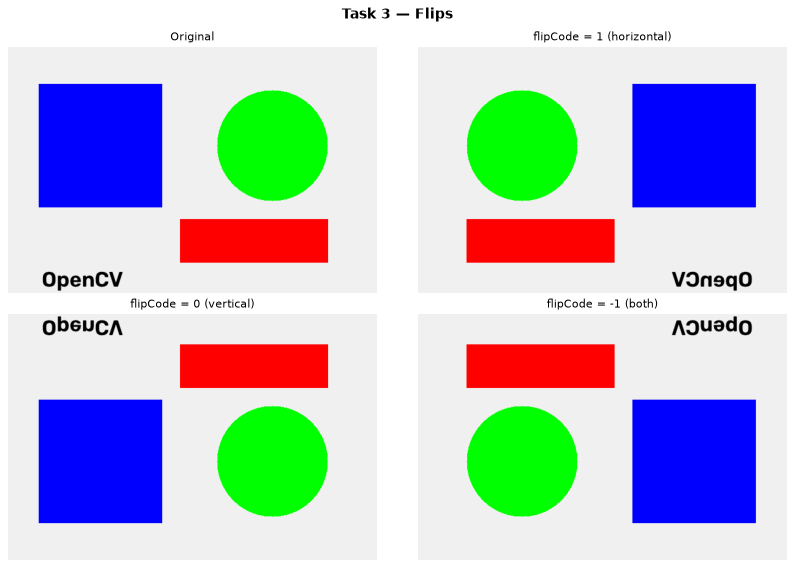

flip(-1) == rotate 180°: True


In [55]:
flip_h = cv2.flip(img, 1)     # horizontal: around the vertical axis
flip_v = cv2.flip(img, 0)     # vertical:   around the horizontal axis
flip_hv = cv2.flip(img, -1)   # both directions

show_grid([img, flip_h, flip_v, flip_hv],
          ["Original", "flipCode = 1 (horizontal)", "flipCode = 0 (vertical)", "flipCode = -1 (both)"],
          cols=2, cell_size=(5.2, 3.6), suptitle="Task 3 — Flips")

# Sanity check: flipping in both directions is the same as a 180° rotation
print("flip(-1) == rotate 180°:", np.array_equal(flip_hv, cv2.rotate(img, cv2.ROTATE_180)))

### Task 4 — Rotate (Solution)

`cv2.getRotationMatrix2D(center, angle, scale)` builds the 2×3 matrix and `cv2.warpAffine()` applies it. In OpenCV a **positive angle rotates counter-clockwise**, a negative angle clockwise.

**Why the corners get cut:** `warpAffine` writes into an output canvas of the size we give it. If we keep the original `w × h`, the rotated rectangle is bigger than that canvas, so its corners fall outside and are lost. The *no-cropping* version computes the bounding box of the rotated image

`new_w = h·|sin θ| + w·|cos θ|`,  `new_h = h·|cos θ| + w·|sin θ|`

and shifts the translation part of the matrix (`M[0, 2]`, `M[1, 2]`) by `(new_w/2 − cx, new_h/2 − cy)` so the rotated image is centred on the bigger canvas.

angle -40°: same-size canvas 600x400  ->  no-crop canvas 717x693
angle +45°: same-size canvas 600x400  ->  no-crop canvas 708x708
angle +80°: same-size canvas 600x400  ->  no-crop canvas 499x661

Rotation matrix for +45° (same size):
 [[  0.707   0.707 -53.553]
 [ -0.707   0.707 270.711]]


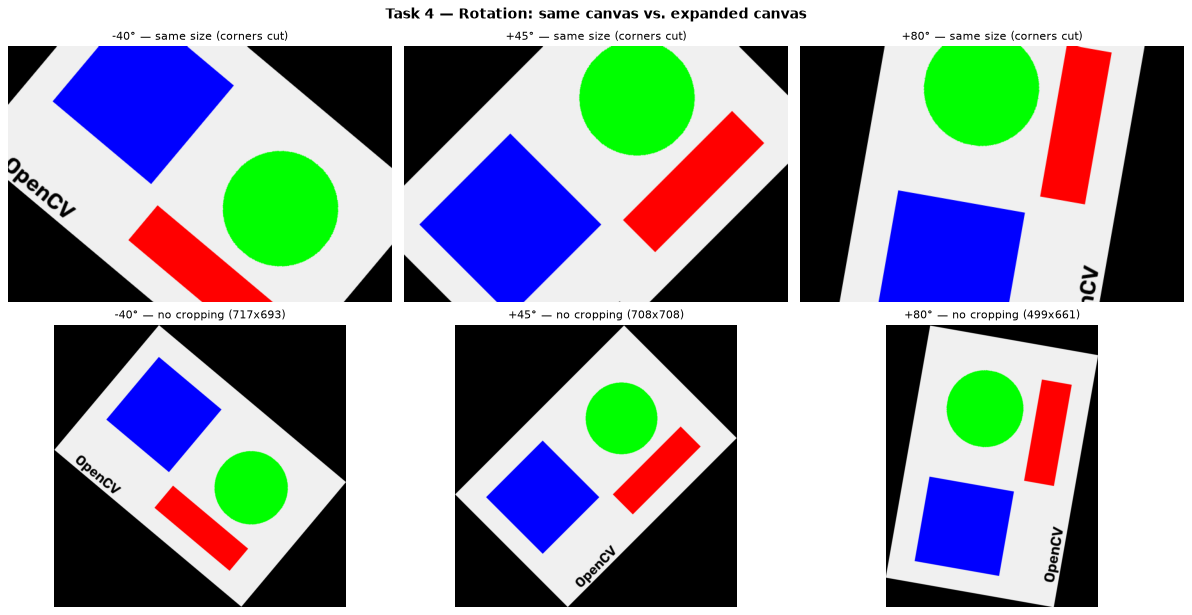

In [56]:
def rotate_same_size(image, angle, border=(0, 0, 0)):
    # Rotate around the image center and keep the original canvas size (corners get cut).
    hh, ww = image.shape[:2]
    M = cv2.getRotationMatrix2D((ww / 2, hh / 2), angle, 1.0)
    return cv2.warpAffine(image, M, (ww, hh), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_CONSTANT, borderValue=border)

def rotate_no_crop(image, angle, border=(0, 0, 0)):
    # Rotate and EXPAND the canvas so the whole rotated image stays visible.
    hh, ww = image.shape[:2]
    cx, cy = ww / 2, hh / 2
    M = cv2.getRotationMatrix2D((cx, cy), angle, 1.0)
    cos, sin = abs(M[0, 0]), abs(M[0, 1])
    new_w = int(np.ceil(hh * sin + ww * cos))     # bounding box of the rotated image
    new_h = int(np.ceil(hh * cos + ww * sin))
    M[0, 2] += new_w / 2 - cx                     # move the center to the center of the new canvas
    M[1, 2] += new_h / 2 - cy
    rotated = cv2.warpAffine(image, M, (new_w, new_h), flags=cv2.INTER_LINEAR,
                             borderMode=cv2.BORDER_CONSTANT, borderValue=border)
    return rotated, M

angles = [-40, 45, 80]
# A black border makes the edges of the rotated image (and the cut corners) easy to see.
same_size = [rotate_same_size(img, a) for a in angles]
no_crop = [rotate_no_crop(img, a) for a in angles]

for a, (rot, M_nc) in zip(angles, no_crop):
    print(f"angle {a:+d}°: same-size canvas {img.shape[1]}x{img.shape[0]}  ->  "
          f"no-crop canvas {rot.shape[1]}x{rot.shape[0]}")
print("\nRotation matrix for +45° (same size):\n", cv2.getRotationMatrix2D((img.shape[1] / 2, img.shape[0] / 2), 45, 1.0).round(3))

show_grid(same_size + [r for r, _ in no_crop],
          [f"{a:+d}° — same size (corners cut)" for a in angles] +
          [f"{a:+d}° — no cropping ({r.shape[1]}x{r.shape[0]})" for a, (r, _) in zip(angles, no_crop)],
          cols=3, cell_size=(5.0, 3.9), suptitle="Task 4 — Rotation: same canvas vs. expanded canvas")

### Task 5 — Annotation in Magenta (Solution)

Magenta in OpenCV's **BGR** order is `(255, 0, 255)` (blue + red, no green). All shapes are drawn on one copy of the image with anti-aliased lines (`cv2.LINE_AA`).

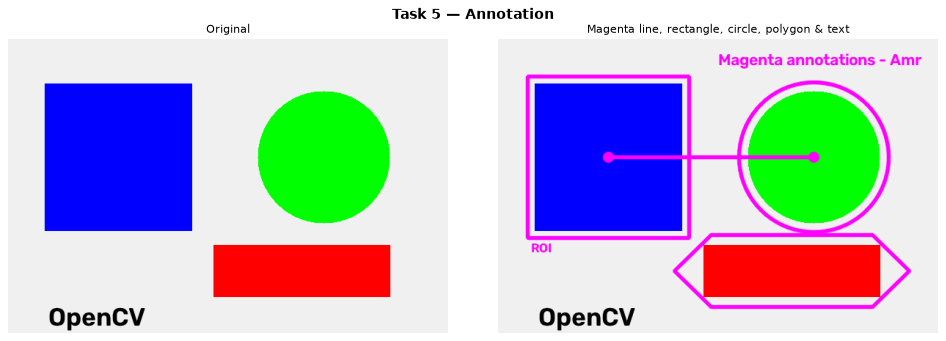

In [57]:
MAGENTA = (255, 0, 255)          # BGR
annotated = img.copy()           # never draw on the original

# 1) Line: connects the center of the blue square to the center of the green circle
cv2.line(annotated, (150, 160), (430, 160), MAGENTA, 3, cv2.LINE_AA)

# 2) Rectangle: outline around the blue square
cv2.rectangle(annotated, (40, 50), (260, 270), MAGENTA, 3, cv2.LINE_AA)

# 3) Circle: outline around the green circle + small filled dots at the line ends
cv2.circle(annotated, (430, 160), 102, MAGENTA, 3, cv2.LINE_AA)
for center in [(150, 160), (430, 160)]:
    cv2.circle(annotated, center, 7, MAGENTA, cv2.FILLED, cv2.LINE_AA)

# 4) Polygon: a closed hexagon around the red rectangle
hexagon = np.array([[240, 315], [290, 266], [510, 266], [560, 315], [510, 364], [290, 364]],
                   dtype=np.int32).reshape(-1, 1, 2)
cv2.polylines(annotated, [hexagon], True, MAGENTA, 3, cv2.LINE_AA)

# 5) Text
cv2.putText(annotated, "Magenta annotations - Amr", (300, 35),
            cv2.FONT_HERSHEY_SIMPLEX, 0.75, MAGENTA, 2, cv2.LINE_AA)
cv2.putText(annotated, "ROI", (45, 290), cv2.FONT_HERSHEY_SIMPLEX, 0.6, MAGENTA, 2, cv2.LINE_AA)

show_grid([img, annotated], ["Original", "Magenta line, rectangle, circle, polygon & text"],
          cols=2, cell_size=(6.2, 4.3), suptitle="Task 5 — Annotation")

### Task 6 — HSV Mask (Solution)

Goal: isolate the **red rectangle**. Red is special in HSV because the hue circle wraps around: red sits at both ends of OpenCV's hue range (`H ≈ 0–10` **and** `H ≈ 170–179`). So two `inRange()` masks are created and combined with `cv2.bitwise_or()`. A minimum saturation and value remove the gray background (S = 0) and the black text (V = 0).

HSV of a red pixel (x=400, y=315): [  0 255 255]
HSV of the background (x=10, y=10): [  0   0 240]

Range 1: lower [  0 100  80]  upper [ 10 255 255]
Range 2: lower [170 100  80]  upper [179 255 255]

Pixels in range 1: 17111,  range 2: 0,  combined: 17111
Expected red-rectangle area: 241 x 71 = 17111
Bounding box of the mask (x, y, w, h): (280, 280, 241, 71)


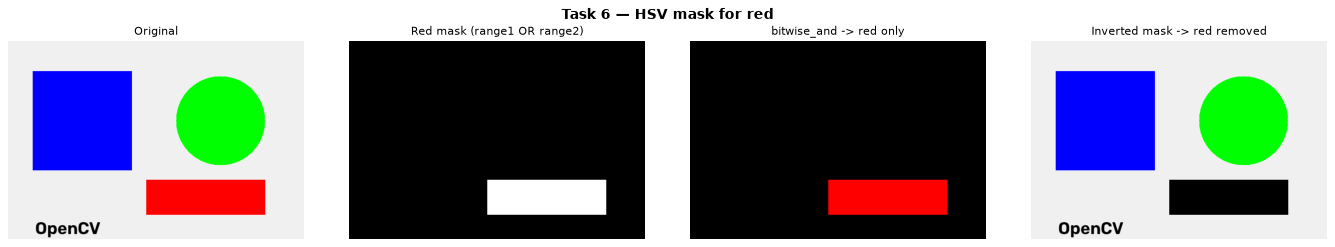

In [58]:
hsv_img = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
print("HSV of a red pixel (x=400, y=315):", hsv_img[315, 400])
print("HSV of the background (x=10, y=10):", hsv_img[10, 10])

# Two ranges because red wraps around hue 0 / 180
lower_red1, upper_red1 = np.array([0, 100, 80]), np.array([10, 255, 255])
lower_red2, upper_red2 = np.array([170, 100, 80]), np.array([179, 255, 255])
print("\nRange 1: lower", lower_red1, " upper", upper_red1)
print("Range 2: lower", lower_red2, " upper", upper_red2)

mask1 = cv2.inRange(hsv_img, lower_red1, upper_red1)
mask2 = cv2.inRange(hsv_img, lower_red2, upper_red2)
red_mask = cv2.bitwise_or(mask1, mask2)              # union of both hue ranges

red_only = cv2.bitwise_and(img, img, mask=red_mask)                       # keep only red pixels
without_red = cv2.bitwise_and(img, img, mask=cv2.bitwise_not(red_mask))   # everything except red

print(f"\nPixels in range 1: {cv2.countNonZero(mask1)},  range 2: {cv2.countNonZero(mask2)},  "
      f"combined: {cv2.countNonZero(red_mask)}")
print("Expected red-rectangle area: 241 x 71 =", 241 * 71)
print("Bounding box of the mask (x, y, w, h):", cv2.boundingRect(red_mask))

show_grid([img, red_mask, red_only, without_red],
          ["Original", "Red mask (range1 OR range2)", "bitwise_and -> red only", "Inverted mask -> red removed"],
          cols=4, cell_size=(4.3, 3.1), suptitle="Task 6 — HSV mask for red")

The mask contains exactly the 241 × 71 pixels of the red rectangle and its bounding box is `(280, 280, 241, 71)` — the blue square, green circle, black text and gray background are all excluded. In this synthetic image pure red has `H = 0`, so only range 1 is used; in real photos many red pixels have `H ≈ 170–179`, which is why the second range is needed.

### Task 7 — Augmentation function (Solution)

`augment_image()` applies the selected augmentations in a sensible order:

1. **Geometric**: flip → rotation + translation (one `warpAffine`) → crop (resized back to the original size so every training image has the same shape)
2. **Photometric**: contrast/brightness → hue shift
3. **Quality**: blur → Gaussian noise (noise last, so the blur does not remove it)

With `random=True` the parameters are sampled from reasonable ranges; `seed` makes the result reproducible. Empty areas created by rotation/translation are filled with `BORDER_REFLECT_101` (as in the lecture), so mirrored pieces of the scene can appear near the borders.

In [59]:
def augment_image(image, flip=None, angle=0.0, tx=0, ty=0, crop_ratio=None,
                  brightness=0, contrast=1.0, hue_shift=0, noise_std=0.0, blur_ksize=0,
                  seed=None, random=False, return_params=False):
    '''
    Create an augmented copy of a BGR image (the input image is not modified).

    Parameters
    ----------
    image       : BGR uint8 image.
    flip        : None (no flip), 1 (horizontal), 0 (vertical) or -1 (both).
    angle       : rotation in degrees around the image center (positive = counter-clockwise).
    tx, ty      : translation in pixels (right / down are positive).
    crop_ratio  : None, or a value in (0, 1] -> crop that fraction of width/height and
                  resize back to the original size (center crop, random position if random=True).
    brightness  : value added to every pixel (beta), e.g. -40 ... +40.
    contrast    : multiplier (alpha), e.g. 0.7 ... 1.3.
    hue_shift   : shift of the HSV hue channel (OpenCV hue range 0-179, wraps around).
    noise_std   : standard deviation of additive Gaussian noise (0 = off).
    blur_ksize  : Gaussian blur kernel size (0 = off; even values are made odd).
    seed        : seed for the random generator (reproducible results).
    random      : if True, ignore the manual values and sample all parameters randomly.
    return_params : if True, return (augmented_image, params_dict).
    '''
    rng = np.random.default_rng(seed)
    hh, ww = image.shape[:2]

    if random:   # sample every parameter from a realistic range
        flip = [None, 1, 0, -1][rng.choice(4, p=[0.4, 0.4, 0.1, 0.1])]   # horizontal flip most common
        angle = round(float(rng.uniform(-20, 20)), 1) + 0.0                # + 0.0 turns -0.0 into 0.0
        tx = int(rng.integers(-ww // 10, ww // 10 + 1))
        ty = int(rng.integers(-hh // 10, hh // 10 + 1))
        crop_ratio = round(float(rng.uniform(0.75, 0.95)), 2) if rng.random() < 0.5 else None
        brightness = int(rng.integers(-40, 41))
        contrast = round(float(rng.uniform(0.7, 1.3)), 2)
        hue_shift = int(rng.integers(-20, 21)) if rng.random() < 0.5 else 0
        noise_std = round(float(rng.uniform(3, 10)), 1) if rng.random() < 0.3 else 0.0
        blur_ksize = int(rng.choice([0, 0, 3, 5]))

    out = image.copy()

    # --- 1. Geometric -------------------------------------------------------------
    if flip is not None:
        out = cv2.flip(out, int(flip))

    if angle != 0 or tx != 0 or ty != 0:
        M = cv2.getRotationMatrix2D((ww / 2, hh / 2), angle, 1.0)
        M[0, 2] += tx                      # add the translation to the same matrix
        M[1, 2] += ty
        out = cv2.warpAffine(out, M, (ww, hh), flags=cv2.INTER_LINEAR,
                             borderMode=cv2.BORDER_REFLECT_101)

    if crop_ratio is not None and crop_ratio < 1.0:
        ch, cw = int(hh * crop_ratio), int(ww * crop_ratio)
        if random:
            y0 = int(rng.integers(0, hh - ch + 1))
            x0 = int(rng.integers(0, ww - cw + 1))
        else:
            y0, x0 = (hh - ch) // 2, (ww - cw) // 2
        out = cv2.resize(out[y0:y0 + ch, x0:x0 + cw], (ww, hh), interpolation=cv2.INTER_LINEAR)

    # --- 2. Photometric -----------------------------------------------------------
    if contrast != 1.0 or brightness != 0:
        # alpha * pixel + beta, clipped to 0..255
        # (np.clip instead of cv2.convertScaleAbs, which would turn negative values positive)
        out = np.clip(out.astype(np.float32) * contrast + brightness, 0, 255).astype(np.uint8)

    if hue_shift != 0:
        hsv = cv2.cvtColor(out, cv2.COLOR_BGR2HSV).astype(np.int16)
        hsv[:, :, 0] = (hsv[:, :, 0] + hue_shift) % 180          # hue is circular (0-179)
        out = cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2BGR)

    # --- 3. Quality: blur, then noise -------------------------------------------------
    if blur_ksize and blur_ksize > 1:
        k = int(blur_ksize) | 1                                   # kernel size must be odd
        out = cv2.GaussianBlur(out, (k, k), 0)

    if noise_std > 0:
        noise = rng.normal(0, noise_std, out.shape)
        out = np.clip(out.astype(np.float32) + noise, 0, 255).astype(np.uint8)

    params = dict(flip=flip, angle=angle, tx=tx, ty=ty, crop_ratio=crop_ratio,
                  brightness=brightness, contrast=contrast, hue_shift=hue_shift,
                  noise_std=noise_std, blur_ksize=blur_ksize)
    return (out, params) if return_params else out


def describe(p):
    # Short title text listing only the augmentations that were actually applied.
    parts = []
    if p["flip"] is not None:     parts.append(f"flip={p['flip']}")
    if p["angle"]:                parts.append(f"rot={p['angle']:+.0f}°")
    if p["tx"] or p["ty"]:        parts.append(f"t=({p['tx']},{p['ty']})")
    if p["crop_ratio"]:           parts.append(f"crop={p['crop_ratio']:.2f}")
    if p["brightness"]:           parts.append(f"b={p['brightness']:+d}")
    if p["contrast"] != 1.0:      parts.append(f"c={p['contrast']:.2f}")
    if p["hue_shift"]:            parts.append(f"hue={p['hue_shift']:+d}")
    if p["blur_ksize"]:           parts.append(f"blur={p['blur_ksize']}")
    if p["noise_std"]:            parts.append(f"noise={p['noise_std']:.0f}")
    if not parts:
        return "no change"
    half = (len(parts) + 1) // 2                                  # wrap onto two lines
    return ", ".join(parts[:half]) + ("\n" + ", ".join(parts[half:]) if parts[half:] else "")

help(augment_image)

Help on function augment_image in module __main__:

augment_image(
    image,
    flip=None,
    angle=0.0,
    tx=0,
    ty=0,
    crop_ratio=None,
    brightness=0,
    contrast=1.0,
    hue_shift=0,
    noise_std=0.0,
    blur_ksize=0,
    seed=None,
    random=False,
    return_params=False
)
    Create an augmented copy of a BGR image (the input image is not modified).

    Parameters
    ----------
    image       : BGR uint8 image.
    flip        : None (no flip), 1 (horizontal), 0 (vertical) or -1 (both).
    angle       : rotation in degrees around the image center (positive = counter-clockwise).
    tx, ty      : translation in pixels (right / down are positive).
    crop_ratio  : None, or a value in (0, 1] -> crop that fraction of width/height and
                  resize back to the original size (center crop, random position if random=True).
    brightness  : value added to every pixel (beta), e.g. -40 ... +40.
    contrast    : multiplier (alpha), e.g. 0.7 ... 1.3.
    h

seed=6: flip=1, angle=-6.3, tx=54, ty=-11, crop_ratio=0.95, brightness=-25, contrast=1.1, hue_shift=5, noise_std=0.0, blur_ksize=0
seed=7: flip=1, angle=15.9, tx=9, ty=22, crop_ratio=0.81, brightness=-17, contrast=0.7, hue_shift=0, noise_std=0.0, blur_ksize=5
seed=8: flip=None, angle=19.5, tx=-39, ty=-15, crop_ratio=None, brightness=11, contrast=0.93, hue_shift=15, noise_std=0.0, blur_ksize=0
seed=9: flip=0, angle=-8.5, tx=-47, ty=8, crop_ratio=None, brightness=12, contrast=1.25, hue_shift=0, noise_std=0.0, blur_ksize=3
seed=10: flip=-1, angle=-11.7, tx=35, ty=27, crop_ratio=0.85, brightness=-28, contrast=1.11, hue_shift=0, noise_std=0.0, blur_ksize=0
seed=11: flip=None, angle=0.0, tx=11, ty=8, crop_ratio=0.78, brightness=-8, contrast=0.74, hue_shift=18, noise_std=0.0, blur_ksize=5


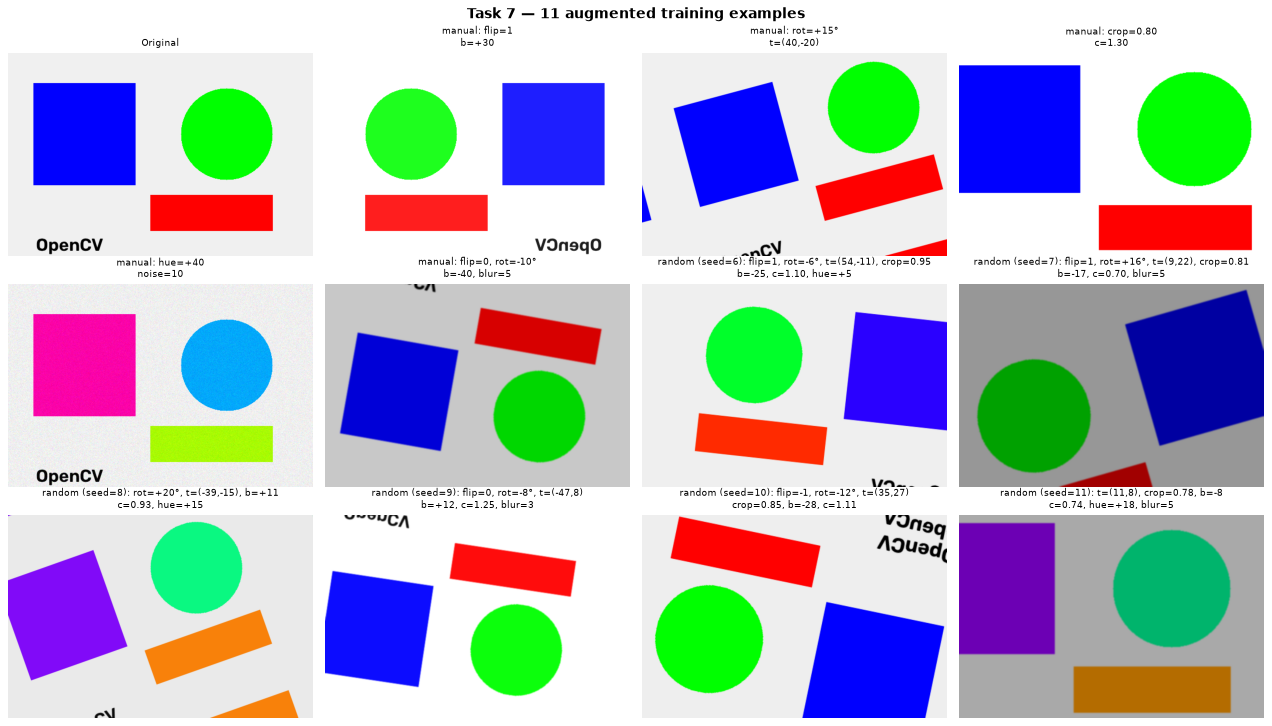


Same seed gives the same image: True
All outputs keep the original shape: True


In [60]:
# 5 hand-picked examples (each focuses on a different kind of augmentation)
manual_settings = [
    dict(flip=1, brightness=30),
    dict(angle=15, tx=40, ty=-20),
    dict(crop_ratio=0.8, contrast=1.3),
    dict(hue_shift=40, noise_std=10, seed=1),
    dict(flip=0, angle=-10, brightness=-40, blur_ksize=5),
]
# 6 random examples (any seeds work; fixed seeds make the notebook reproducible)
random_seeds = [6, 7, 8, 9, 10, 11]

images, titles = [img], ["Original"]
for s in manual_settings:
    aug, p = augment_image(img, return_params=True, **s)
    images.append(aug)
    titles.append("manual: " + describe(p))
for seed in random_seeds:
    aug, p = augment_image(img, random=True, seed=seed, return_params=True)
    images.append(aug)
    titles.append(f"random (seed={seed}): " + describe(p))
    print(f"seed={seed}: " + ", ".join(f"{k}={v}" for k, v in p.items()))

show_grid(images, titles, cols=4, cell_size=(4.0, 3.1), title_size=8.5,
          suptitle=f"Task 7 — {len(images) - 1} augmented training examples")

# Same seed -> identical result (reproducible); the input image is never modified
a = augment_image(img, random=True, seed=3)
b = augment_image(img, random=True, seed=3)
print("\nSame seed gives the same image:", np.array_equal(a, b))
print("All outputs keep the original shape:", all(im.shape == img.shape for im in images))

### Task 8 — Label Preservation (Solution)

Bounding box of the **blue square**: `(x1, y1, x2, y2) = (50, 60, 250, 260)` — the same corner pixels used to draw it.

Pixel indices run from `0` to `W − 1`, so after a flip a pixel at column `x` moves to column `W − 1 − x` (and row `y` to `H − 1 − y` for a vertical flip). Because the order of the corners is reversed, the new box is:

| Flip | new x1, x2 | new y1, y2 |
|---|---|---|
| horizontal (`1`) | `W−1−x2`, `W−1−x1` | unchanged |
| vertical (`0`) | unchanged | `H−1−y2`, `H−1−y1` |
| both (`-1`) | `W−1−x2`, `W−1−x1` | `H−1−y2`, `H−1−y1` |

(The lecture formula `W − x2` treats the corners as continuous edges; with pixel-index corners the `−1` makes the box match the object exactly.)

Image size: W=600, H=400
version                computed box   measured from pixels  match
original         (50, 60, 250, 260)     (50, 60, 250, 260)  True
horizontal      (349, 60, 549, 260)    (349, 60, 549, 260)  True
vertical        (50, 139, 250, 339)    (50, 139, 250, 339)  True
both           (349, 139, 549, 339)   (349, 139, 549, 339)  True


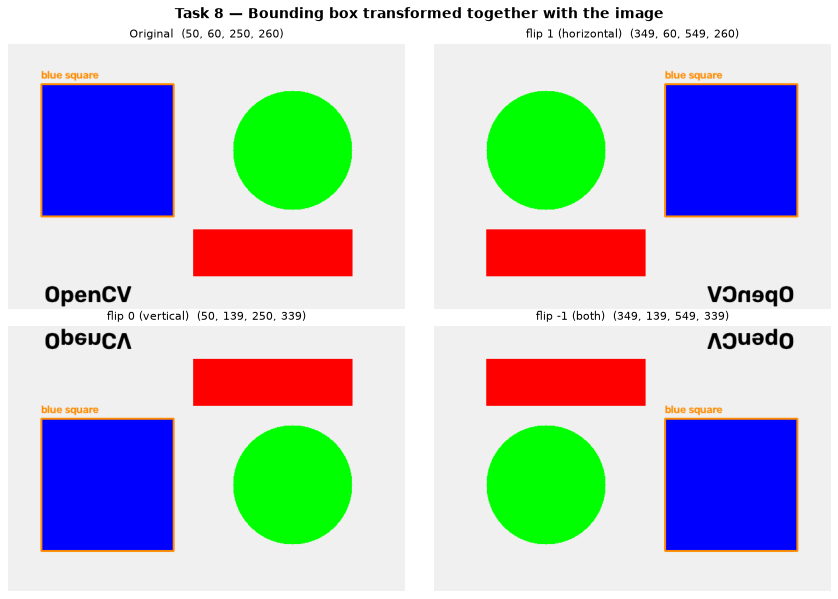

In [61]:
def flip_bbox(box, img_w, img_h, flip_code):
    # Return the bounding box (x1, y1, x2, y2) after cv2.flip(image, flip_code).
    x1, y1, x2, y2 = box
    if flip_code in (1, -1):                 # horizontal -> mirror the x coordinates
        x1, x2 = img_w - 1 - x2, img_w - 1 - x1
    if flip_code in (0, -1):                 # vertical   -> mirror the y coordinates
        y1, y2 = img_h - 1 - y2, img_h - 1 - y1
    return (x1, y1, x2, y2)

def measured_blue_box(image):
    # Ground truth for checking: bounding box of the pure-blue pixels in the image.
    mask = cv2.inRange(image, (200, 0, 0), (255, 60, 60))
    x, y, bw, bh = cv2.boundingRect(mask)
    return (x, y, x + bw - 1, y + bh - 1)

def draw_box(image, box, color=(0, 140, 255), label=None):
    out = image.copy()
    cv2.rectangle(out, box[:2], box[2:], color, 2)
    if label:
        cv2.putText(out, label, (box[0], max(box[1] - 8, 15)), cv2.FONT_HERSHEY_SIMPLEX,
                    0.55, color, 2, cv2.LINE_AA)
    return out

H_img, W_img = img.shape[:2]
blue_box = (50, 60, 250, 260)
print(f"Image size: W={W_img}, H={H_img}")
print(f"{'version':12s} {'computed box':>22s} {'measured from pixels':>22s}  match")
print(f"{'original':12s} {str(blue_box):>22s} {str(measured_blue_box(img)):>22s}  "
      f"{blue_box == measured_blue_box(img)}")

panels, panel_titles = [draw_box(img, blue_box, label="blue square")], [f"Original  {blue_box}"]
for code_, name in [(1, "horizontal"), (0, "vertical"), (-1, "both")]:
    flipped = cv2.flip(img, code_)
    new_box = flip_bbox(blue_box, W_img, H_img, code_)
    measured = measured_blue_box(flipped)
    print(f"{name:12s} {str(new_box):>22s} {str(measured):>22s}  {new_box == measured}")
    panels.append(draw_box(flipped, new_box, label="blue square"))
    panel_titles.append(f"flip {code_} ({name})  {new_box}")

show_grid(panels, panel_titles, cols=2, cell_size=(5.4, 3.8),
          suptitle="Task 8 — Bounding box transformed together with the image")

The computed boxes are identical to the boxes measured directly from the blue pixels of each flipped image, so the label still encloses the object exactly.

**Bonus — rotation.** A rotated box is no longer axis-aligned, so we transform its **4 corners** with the same 2×3 matrix `M` used for the image (`[x', y'] = M · [x, y, 1]`) and take the min/max of the new corners as the new axis-aligned box (the *envelope*), clipped to the image.

Rotation: 25° around the image center
Rotated corners:
 [[ 14.3 178.8]
 [195.5  94.2]
 [280.  275.5]
 [ 98.8 360. ]]
New axis-aligned box (envelope): (14, 94, 281, 361)
Box measured from blue pixels:   (15, 95, 280, 360)


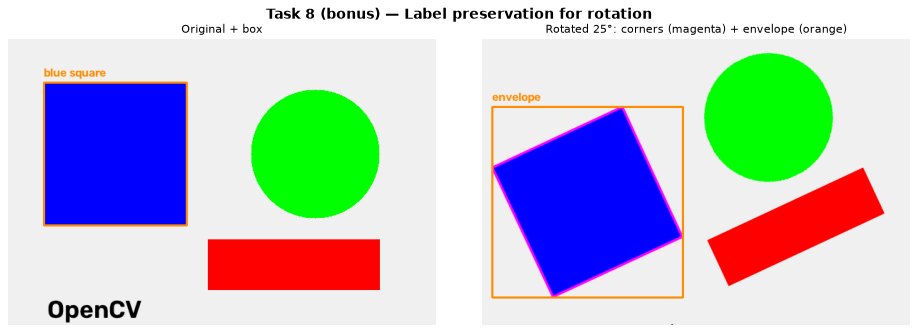

In [62]:
def rotate_bbox(box, M, img_w, img_h):
    # Transform the 4 corners of an axis-aligned box with the 2x3 affine matrix M.
    x1, y1, x2, y2 = box
    corners = np.array([[x1, y1], [x2, y1], [x2, y2], [x1, y2]], dtype=np.float64)
    ones = np.ones((4, 1))
    new_corners = np.hstack([corners, ones]) @ M.T           # (4x3) @ (3x2) -> (4x2)
    nx1, ny1 = new_corners.min(axis=0)
    nx2, ny2 = new_corners.max(axis=0)
    envelope = (int(np.clip(np.floor(nx1), 0, img_w - 1)), int(np.clip(np.floor(ny1), 0, img_h - 1)),
                int(np.clip(np.ceil(nx2), 0, img_w - 1)), int(np.clip(np.ceil(ny2), 0, img_h - 1)))
    return new_corners, envelope

rot_angle = 25
M_rot = cv2.getRotationMatrix2D((W_img / 2, H_img / 2), rot_angle, 1.0)
rotated_img = cv2.warpAffine(img, M_rot, (W_img, H_img), flags=cv2.INTER_LINEAR,
                             borderMode=cv2.BORDER_CONSTANT, borderValue=(240, 240, 240))

new_corners, envelope = rotate_bbox(blue_box, M_rot, W_img, H_img)
print(f"Rotation: {rot_angle}° around the image center")
print("Rotated corners:\n", new_corners.round(1))
print("New axis-aligned box (envelope):", envelope)
print("Box measured from blue pixels:  ", measured_blue_box(rotated_img))

rot_vis = rotated_img.copy()
cv2.polylines(rot_vis, [np.round(new_corners).astype(np.int32).reshape(-1, 1, 2)], True,
              (255, 0, 255), 2, cv2.LINE_AA)                                 # exact rotated box
rot_vis = draw_box(rot_vis, envelope, label="envelope")                        # axis-aligned box

show_grid([draw_box(img, blue_box, label="blue square"), rot_vis],
          ["Original + box", f"Rotated {rot_angle}°: corners (magenta) + envelope (orange)"],
          cols=2, cell_size=(6.0, 4.2), suptitle="Task 8 (bonus) — Label preservation for rotation")

The envelope matches the box measured from the rotated blue pixels (±1 px from interpolation at the edges), so the label is preserved. Note that for general objects the envelope of a rotated box is usually **larger** than the object (it also contains the empty triangles at the corners) — this is why large rotation angles are used carefully when augmenting object-detection data.